# Diniz Ch.3 — LMS inverse-channel equalization

估計 50-tap 等化器，檢查通道與等化器的串接脈衝響應。改用因果 regressor 與明確 decision delay。

來源：`Diniz-Chap3-Channel-Eq.ipynb`。所有資料與結果留在記憶體，圖表使用共用深色風格。

執行順序：設定 → 參數與資料 → 模型與訓練 → 圖表與數值摘要。

## 1. Setup

In [ ]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Parameters and data

In [ ]:
n_samples, n_trials, seed = 100_000, 1, 3
n_taps, decision_delay = 50, 41
h = 0.1 * 0.5**np.arange(9)
noise_var = 10**-2.5
input_variance = np.sum(h**2) + noise_var
mu = 1 / (n_taps * input_variance) / 5
make_data = partial(data.equalization, n_samples, h=h, decision_delay=decision_delay, symbol_kind="bpsk",
                    noise_var=noise_var)
print(f"mu={mu:.6g}, decision delay={decision_delay}, n_taps={n_taps}")

## 3. Model and training

In [ ]:
models = {"LMS": partial(af.LMS, filter_order=n_taps - 1, mu=mu)}
results = training.compare(models, make_data, n_trials=n_trials, seed=seed)
result = results["LMS"].representative
q = np.conj(result.w_final)
cascade = np.convolve(h, q)
print("Cascade peak index:", np.argmax(np.abs(cascade)))

## 4. Plots and summary

In [ ]:
fig, grid = plot.axes(rows=2, cols=2)
plot.stem({"Physical equalizer taps": q.real}, ax=grid[0, 0], title="Equalizer impulse response")
plot.stem({"Channel × equalizer": cascade.real}, ax=grid[0, 1], title="Cascade impulse response")
plot.learning(results, ax=grid[1, 0], window=501)
plot.lines({"Error": result.e[-1000:].real}, x=result.index[-1000:], ax=grid[1, 1], title="Tail error")
plot.show(fig)
training.summary(results, tail=5000)

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

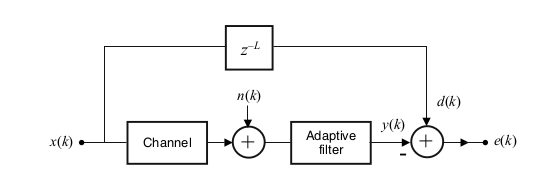